In [48]:
# Data Science, Assignment - 1
# Question 1

# Data Preprocessing
import sklearn
import pandas as pd
import numpy as np

from sklearn.datasets import fetch_kddcup99
kdd = fetch_kddcup99(subset=None, as_frame=True)
X = kdd.data.copy()

print("RAW DATA INFORMATION \n")
print("Rows (raw data) : ", X.shape[0])
print("Columns (raw data) : ", X.shape[1])
print("Columns in dataset : ")
print(list(X.columns))

# Raw Data Transformation with one hot encoding, removing constant columns, and normalisation. 
print("\n")
one_hot_cols = ['protocol_type', 'service', 'flag']
numeric_cols = [c for c in X.columns if c not in one_hot_cols]
X[numeric_cols] = X[numeric_cols].astype(float)
X = pd.get_dummies(X, columns=one_hot_cols) 
X = X.loc[:, X.nunique()>1] 
D = X.to_numpy(dtype=np.float32)
D = (D - D.min(axis=0))/(D.max(axis=0) - D.min(axis=0)) 


print("TRANSFORMED DATA INFORMATION \n")
print("Rows (data matrix) : ", D.shape[0])
print("Columns (data matrix): ", D.shape[1])
print("Columns in dataset : ")
print(list(X.columns))
print(D.shape)
print("\n")

RAW DATA INFORMATION 

Rows (raw data) :  494021
Columns (raw data) :  41
Columns in dataset : 
['duration', 'protocol_type', 'service', 'flag', 'src_bytes', 'dst_bytes', 'land', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'logged_in', 'num_compromised', 'root_shell', 'su_attempted', 'num_root', 'num_file_creations', 'num_shells', 'num_access_files', 'num_outbound_cmds', 'is_host_login', 'is_guest_login', 'count', 'srv_count', 'serror_rate', 'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate', 'same_srv_rate', 'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_count', 'dst_host_srv_count', 'dst_host_same_srv_rate', 'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate', 'dst_host_srv_diff_host_rate', 'dst_host_serror_rate', 'dst_host_srv_serror_rate', 'dst_host_rerror_rate', 'dst_host_srv_rerror_rate']


TRANSFORMED DATA INFORMATION 

Rows (data matrix) :  494021
Columns (data matrix):  116
Columns in dataset : 
['duration', 'src_bytes', 'dst_bytes', 'land', 'wrong_fragment'

In [49]:
# JL for k-means clustering [Q1]

# Part - (a) Running k-means on D.
from sklearn.cluster import KMeans
import time

# cost function computation using the expanded formula. 
def cost(D, B, labels=None):
    D_sq = (D ** 2).sum(axis=1)[:, None]
    B_sq = (B ** 2).sum(axis=1)[None, :]
    M = D_sq + B_sq - 2 * (D @ B.T)
    M = np.maximum(M, 0)
    if labels is None:
        return M.min(axis=1).sum()                         
    return M[np.arange(D.shape[0]), labels].sum() 

kmeans = KMeans(n_clusters=15, n_init=5, random_state=42)
t0 = time.perf_counter()
kmeans.fit(D)
t1 = time.perf_counter()
time_taken = t1 - t0

B      = kmeans.cluster_centers_
labels = kmeans.labels_
cost_B = cost(D, B)

print("Centers : ", B)
print("Clustering Cost:", cost_B)
print("Wall-Clock Time of Run:", time_taken)

Centers :  [[-1.36671588e-07  1.34971015e-06  6.62403181e-08 ... -7.58700480e-09
   1.00006735e+00  7.15663191e-08]
 [-8.27130862e-08  1.15032444e-05  1.59635965e-06 ...  1.15021467e-05
   2.33113766e-04  1.20799069e-03]
 [ 8.85926420e-06  1.61420962e-06  9.96662187e-04 ...  6.59551006e-05
   9.96390343e-01  2.06346158e-08]
 ...
 [ 1.47653860e-04  8.50961897e-07  6.51475566e-05 ...  2.00088834e-11
   9.91166472e-01  6.54836185e-10]
 [ 1.03756145e-04  2.98638770e-06  7.15978749e-05 ...  6.18456397e-11
   9.97430623e-01  9.02218744e-10]
 [ 1.07270898e-06  2.11347015e-07  4.27826308e-09 ...  1.63709046e-11
   1.00000072e+00  8.29459168e-10]]
Clustering Cost: 53883.152
Wall-Clock Time of Run: 5.155192915997759


m= 5  cost=69368.37  ratio=1.2874  ratio_new=78.4104, time=1.0039
m= 5  cost=76626.66  ratio=1.4221  ratio_new=77.9414, time=1.0781
m= 5  cost=53539.17  ratio=0.9936  ratio_new=79.2347, time=1.0485
m= 5  cost=66364.52  ratio=1.2316  ratio_new=78.2614, time=1.0200
m= 5  cost=65464.13  ratio=1.2149  ratio_new=74.9883, time=1.0284
m=10  cost=58134.39  ratio=1.0789  ratio_new=73.4280, time=1.0834
m=10  cost=61997.46  ratio=1.1506  ratio_new=75.4574, time=1.0638
m=10  cost=57749.00  ratio=1.0717  ratio_new=76.4592, time=1.2031
m=10  cost=53436.37  ratio=0.9917  ratio_new=76.3164, time=0.9912
m=10  cost=55402.54  ratio=1.0282  ratio_new=76.4358, time=1.0278
m=15  cost=60542.42  ratio=1.1236  ratio_new=68.9765, time=1.3795
m=15  cost=55477.84  ratio=1.0296  ratio_new=75.8056, time=1.1133
m=15  cost=54892.04  ratio=1.0187  ratio_new=69.9878, time=1.0724
m=15  cost=53630.45  ratio=0.9953  ratio_new=76.1879, time=1.0970
m=15  cost=55631.69  ratio=1.0325  ratio_new=75.4175, time=1.1298
m=20  cost

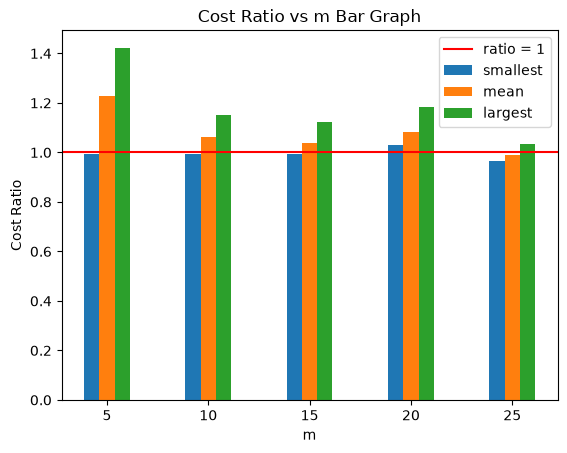

Average Time per m : 
m
5     1.035781
10    1.073889
15    1.158391
20    1.159628
25    1.283752
Name: run_time, dtype: float64


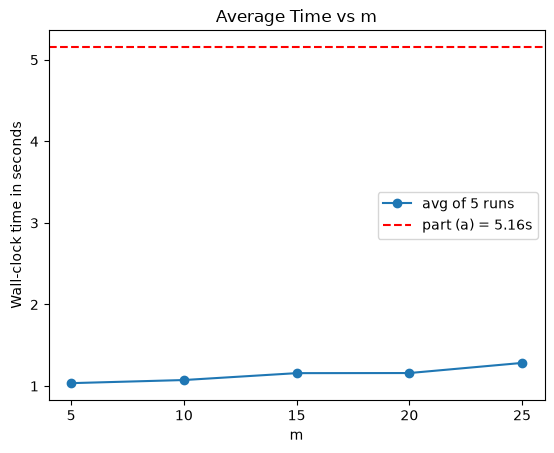

In [ ]:
# Part (b), (c), (d) (common code)
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
results = []
saved_runs = []

for m in [5, 10, 15, 20, 25]:
  for i in range(5):
    A = rng.normal(loc=0, scale=1/np.sqrt(m), size=(m, D.shape[1])).astype(np.float32)
    start_time = time.perf_counter()
    E = D @ A.T
    kmeans_proj = KMeans(n_clusters=15, n_init=5, random_state=42)
    kmeans_proj.fit(E)
    end_time = time.perf_counter()
    run_time = end_time - start_time

    labels_E = kmeans_proj.labels_
    B_hat = np.array([D[labels_E == j].mean(axis=0) for j in range(15)])
    cost_B_hat = cost(D, B_hat)
    ratio = cost_B_hat / cost_B

    # mapping the cluster centers from projected space back to original space
    centers_E = kmeans_proj.cluster_centers_
    A_pseudo_inv = np.linalg.pinv(A)
    B_plus = centers_E @ A_pseudo_inv.T
    cost_B_new = cost(D, B_plus)
    ratio_new = cost_B_new/cost_B

    results.append({"m": m, "cost_hat": cost_B_hat, "ratio": ratio, "ratio_new": ratio_new, "run_time": run_time})
    print(f"m={m:2d}  cost={cost_B_hat:.2f}  ratio={ratio:.4f}  ratio_new={ratio_new:.4f}, time={run_time:.4f}")

print("\n")
print("TABLE : ")
res_frame = pd.DataFrame(results)
res_table = res_frame.groupby("m")["ratio"].agg(["mean", "min", "max"])
res_frame_new = pd.DataFrame(results)
res_table_new = res_frame_new.groupby("m")["ratio_new"].agg(["mean", "min", "max"])
print(pd.concat([res_table, res_table_new], axis=1, keys=["B_hat", "B_new"]))

# code for bar graph
x = np.arange(len(res_table))      
w = 0.15                          
plt.bar(x - w, res_table["min"],  width=w, label="smallest")
plt.bar(x,     res_table["mean"], width=w, label="mean")
plt.bar(x + w, res_table["max"],  width=w, label="largest")
plt.axhline(1, color="red", linestyle="-", label="ratio = 1")
plt.xticks(x, res_table.index)    
plt.xlabel("m")
plt.ylabel("Cost Ratio")
plt.title("Cost Ratio vs m Bar Graph")
plt.legend()
plt.show()

# average time taken for each m and plotting 
time_avg = res_frame.groupby("m")["run_time"].mean()
print("Average Time per m : ")
print(time_avg)

plt.figure()
plt.plot(time_avg.index, time_avg.values, marker="o", label="avg of 5 runs")
plt.axhline(time_taken, color="red", linestyle="--", label=f"part (a) = {time_taken:.2f}s")
plt.xticks(time_avg.index)
plt.xlabel("m")
plt.ylabel("Wall-clock time in seconds")
plt.title("Average Time vs m")
plt.legend()
plt.show()




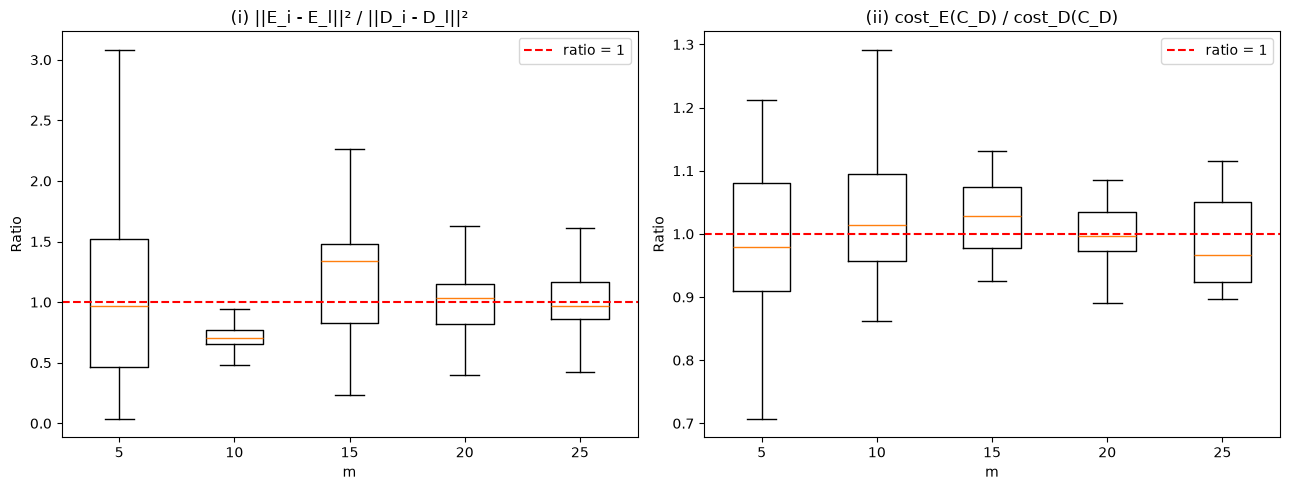

In [51]:
# Part (e) 
rng_e = np.random.default_rng(42)
n = D.shape[0]
pairs = []
while(len(pairs) < 1e4):
    i, j = rng_e.integers(0, n, size=2)
    if not np.array_equal(D[i], D[j]):
        pairs.append((i, j))
pairs = np.array(pairs)
I = pairs[:, 0]
L = pairs[:, 1]
dist = np.sum((D[I] - D[L])**2, axis=1)

cost_D_CD = cost(D, B, labels)

pair_ratios = []
cost_ratios = []

for m in [5, 10, 15, 20, 25]:
    A = rng_e.normal(loc=0, scale=1/np.sqrt(m), size=(m, D.shape[1])).astype(np.float32)
    E = D @ A.T
    dist_E = np.sum((E[I] - E[L])**2, axis=1)
    pair_ratio = dist_E / dist
    pair_ratios.append(pair_ratio)

    ratios_m = []
    for t in range(20): 
        A = rng_e.normal(loc=0, scale=1/np.sqrt(m), size=(m, D.shape[1])).astype(np.float32)
        E = D @ A.T
        centres_E = np.array([E[labels == j].mean(axis=0) for j in range(15)])
        ratios_m.append(cost(E, centres_E, labels) / cost_D_CD)
    cost_ratios.append(np.array(ratios_m))

# boxplots 
m_list = [5, 10, 15, 20, 25]
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
pos = np.arange(1, len(m_list) + 1)

axes[0].boxplot(pair_ratios, positions=pos, showfliers=False)
axes[0].axhline(1, color="red", linestyle="--", label="ratio = 1")
axes[0].set_xticks(pos)
axes[0].set_xticklabels(m_list)
axes[0].set_xlabel("m")
axes[0].set_ylabel("Ratio")
axes[0].set_title("(i) ||E_i - E_l||² / ||D_i - D_l||²")
axes[0].legend()

axes[1].boxplot(cost_ratios, positions=pos, showfliers=False)
axes[1].axhline(1, color="red", linestyle="--", label="ratio = 1")
axes[1].set_xticks(pos)
axes[1].set_xticklabels(m_list)
axes[1].set_xlabel("m")
axes[1].set_ylabel("Ratio")
axes[1].set_title("(ii) cost_E(C_D) / cost_D(C_D)")
axes[1].legend()

plt.tight_layout()
plt.show()



